# Task 1 — Exploratory Data Analysis (EDA)

**Dataset:** `final_transcripts(1).json`

This notebook performs a dataset-specific EDA of the conversational transcript dataset before building the Traditional RAG baseline.

### Goals
1. Understand the dataset structure and quality.
2. Analyze domains, intents, and reasons for calls.
3. Analyze conversation and turn-level statistics.
4. Inspect speaker distributions and speaker-role consistency.
5. Study temporal patterns.
6. Analyze text length, vocabulary, filler words, and dialogue behavior.
7. Identify potential data-quality issues.
8. Produce reusable CSV/JSON summaries and publication-ready plots.

> **Important:** The dataset contains `intent` and `reason_for_call`, but it does **not** provide a universal explicit business-event/outcome label. Therefore this EDA does not treat `intent` as an outcome variable.


## 1. Install / import dependencies

The notebook is designed for Kaggle, Colab, or a local Jupyter environment.

If the packages are already installed, the installation cell can be skipped.


In [3]:
# Uncomment if needed
# %pip install -q pandas numpy matplotlib seaborn tqdm wordcloud pyarrow

import json
import re
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42


## 2. Configuration

For Kaggle, upload `final_transcripts(1).json` as a dataset and change `DATA_PATH` if necessary.

For the original uploaded file, the path below is the expected local path.


In [4]:
# Change this path if using Kaggle / Colab
DATA_PATH = Path("/kaggle/input/datasets/freegpu1234576/final-transcribe/final_transcripts.json")

# Common alternatives:
# DATA_PATH = Path("/kaggle/input/<dataset-folder>/final_transcripts(1).json")
# DATA_PATH = Path("/content/final_transcripts(1).json")

OUTPUT_DIR = Path("./task1_eda_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.exists(), (
    f"Dataset not found at {DATA_PATH}. "
    "Update DATA_PATH to the location of final_transcripts(1).json."
)

print("Dataset:", DATA_PATH)
print("Size (MB):", round(DATA_PATH.stat().st_size / (1024**2), 2))
print("Output directory:", OUTPUT_DIR.resolve())


Dataset: /kaggle/input/datasets/freegpu1234576/final-transcribe/final_transcripts.json
Size (MB): 105.94
Output directory: /kaggle/working/task1_eda_outputs


## 3. Load the nested JSON dataset

In [5]:
with open(DATA_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

print("Python object type:", type(data).__name__)
print("Number of conversation records:", len(data))

assert isinstance(data, list), "Expected the root JSON object to be a list."
assert len(data) > 0, "Dataset is empty."

display(pd.DataFrame(data[:3]))


Python object type: list
Number of conversation records: 19621


,transcript_id,time_of_interaction,domain,intent,reason_for_call,conversation
0,ce44aa4b-13b7-4778-b413-15f37ee15f7a,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,"[{'speaker': 'Agent', 'text': 'thank you for calling beachfront suites this is isabella nguyen how can i help you to..."
1,6447a610-7803-4e29-918f-7255ece57195,2025-11-06 12:55:00,Insurance,Booking Errors,Jack Bell called to report and resolve a double-booking issue at LuxStay Hotels in Las Vegas.,"[{'speaker': 'Agent', 'text': 'thank you for calling luxstay hotels this is isabella nguyen how can i assist you tod..."
2,1e47a0f1-6334-45b3-8d04-84f8795d8d60,2025-11-08 16:10:00,Insurance,Booking Errors,"Customer Luke Cook reported a double-booking error at LuxStay Hotels in Chicago, seeking resolution.","[{'speaker': 'Agent', 'text': 'thank you for calling luckstay hotels in chicago this is sarah johnson how can i assi..."


## 4. Validate schema

Expected conversation-level fields:

- `transcript_id`
- `time_of_interaction`
- `domain`
- `intent`
- `reason_for_call`
- `conversation`

Expected turn-level fields:

- `speaker`
- `text`


In [6]:
EXPECTED_RECORD_FIELDS = {
    "transcript_id",
    "time_of_interaction",
    "domain",
    "intent",
    "reason_for_call",
    "conversation",
}

EXPECTED_TURN_FIELDS = {"speaker", "text"}

record_field_counts = Counter()
turn_field_counts = Counter()

for record in data:
    record_field_counts.update(record.keys())
    for turn in record.get("conversation", []):
        turn_field_counts.update(turn.keys())

schema_report = pd.DataFrame({
    "record_field": list(EXPECTED_RECORD_FIELDS),
    "present_count": [record_field_counts[f] for f in EXPECTED_RECORD_FIELDS],
})
schema_report["missing_records"] = len(data) - schema_report["present_count"]

print("Record-level schema")
display(schema_report)

turn_count = sum(len(r.get("conversation", [])) for r in data)

turn_schema_report = pd.DataFrame({
    "turn_field": list(EXPECTED_TURN_FIELDS),
    "present_count": [turn_field_counts[f] for f in EXPECTED_TURN_FIELDS],
})
turn_schema_report["missing_turns"] = turn_count - turn_schema_report["present_count"]

print("Turn-level schema")
display(turn_schema_report)

assert all(f in data[0] for f in EXPECTED_RECORD_FIELDS)


Record-level schema


,record_field,present_count,missing_records
0,intent,19621,0
1,reason_for_call,19621,0
2,conversation,19621,0
3,transcript_id,19621,0
4,domain,19621,0
5,time_of_interaction,19621,0


Turn-level schema


,turn_field,present_count,missing_turns
0,text,686764,0
1,speaker,686764,0


## 5. Build conversation-level DataFrame

In [7]:
records = []

for r in data:
    conversation = r.get("conversation", [])
    records.append({
        "transcript_id": r.get("transcript_id"),
        "time_of_interaction": r.get("time_of_interaction"),
        "domain": r.get("domain"),
        "intent": r.get("intent"),
        "reason_for_call": r.get("reason_for_call"),
        "n_turns": len(conversation),
        "n_speakers": len(set(t.get("speaker", "") for t in conversation)),
        "conversation_text": " ".join(
            str(t.get("text", "")) for t in conversation
        ).strip(),
    })

df = pd.DataFrame(records)

df["time_of_interaction"] = pd.to_datetime(
    df["time_of_interaction"], errors="coerce"
)

df["date"] = df["time_of_interaction"].dt.date
df["hour"] = df["time_of_interaction"].dt.hour
df["day_of_week"] = df["time_of_interaction"].dt.day_name()
df["day_of_week_num"] = df["time_of_interaction"].dt.dayofweek

df["conversation_chars"] = df["conversation_text"].str.len()
df["conversation_words"] = df["conversation_text"].str.split().str.len()

print("Shape:", df.shape)
display(df.head())


Shape: (19621, 14)


,transcript_id,time_of_interaction,domain,intent,reason_for_call,n_turns,n_speakers,conversation_text,date,hour,day_of_week,day_of_week_num,conversation_chars,conversation_words
0,ce44aa4b-13b7-4778-b413-15f37ee15f7a,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,27,2,thank you for calling beachfront suites this is isabella nguyen how can i help you today hi um this is lily kelly i ...,2025-11-10,16,Monday,0,2442,468
1,6447a610-7803-4e29-918f-7255ece57195,2025-11-06 12:55:00,Insurance,Booking Errors,Jack Bell called to report and resolve a double-booking issue at LuxStay Hotels in Las Vegas.,29,2,thank you for calling luxstay hotels this is isabella nguyen how can i assist you today hi this is jack bell i need ...,2025-11-06,12,Thursday,3,2118,409
2,1e47a0f1-6334-45b3-8d04-84f8795d8d60,2025-11-08 16:10:00,Insurance,Booking Errors,"Customer Luke Cook reported a double-booking error at LuxStay Hotels in Chicago, seeking resolution.",29,2,thank you for calling luckstay hotels in chicago this is sarah johnson how can i assist you today hi sarah um this i...,2025-11-08,16,Saturday,5,2724,512
3,1fdc6e49-fdb1-4b0e-9ede-f207389e236e,2025-11-08 15:05:00,Insurance,Discounts & Promotions,"Inquiry about available promotions and discounts at LuxStay Hotels in Miami Beach, with specific interest in seasona...",41,2,thank you for calling luxstay hotels this is emily carter how may i assist you today hi emily this is john ramirez i...,2025-11-08,15,Saturday,5,3338,608
4,d0bb846f-8d9d-4223-9d10-2657c29c4244,2025-11-08 11:13:00,Insurance,Upgrade Requests,Noah Price wanted to explore room upgrade options at CozyInn in Chicago for better amenities.,41,2,thank you for calling cozyinn this is daniel kim how can i help you today hi daniel this is noah price i'm looking t...,2025-11-08,11,Saturday,5,3153,610


## 6. Dataset overview

This section gives the headline statistics that should appear in the EDA/report:

- Number of conversations
- Total turns
- Average/min/max turns
- Unique domains
- Unique intents
- Unique speakers
- Date range
- Missing-value counts


In [8]:
total_conversations = len(df)
total_turns = int(df["n_turns"].sum())

overview = pd.Series({
    "Conversations": total_conversations,
    "Total turns": total_turns,
    "Average turns / conversation": df["n_turns"].mean(),
    "Median turns / conversation": df["n_turns"].median(),
    "Minimum turns": df["n_turns"].min(),
    "Maximum turns": df["n_turns"].max(),
    "Unique domains": df["domain"].nunique(),
    "Unique intents": df["intent"].nunique(),
    "Unique dates": df["date"].nunique(),
    "Date range start": df["time_of_interaction"].min(),
    "Date range end": df["time_of_interaction"].max(),
})

display(overview.to_frame("value"))

print("\nMissing values")
display(df.isna().sum().to_frame("missing_count"))

print("\nDuplicate transcript IDs:", df["transcript_id"].duplicated().sum())


,value
Conversations,19621
Total turns,686764
Average turns / conversation,35.001478
Median turns / conversation,35.0
Minimum turns,1
Maximum turns,79
Unique domains,1
Unique intents,35
Unique dates,9
Date range start,2025-11-04 09:00:00



Missing values


,missing_count
transcript_id,0
time_of_interaction,0
domain,0
intent,0
reason_for_call,0
n_turns,0
n_speakers,0
conversation_text,0
date,0
hour,0



Duplicate transcript IDs: 0


## 7. Domain distribution

,domain,conversation_count,percentage
0,Insurance,19621,100.0


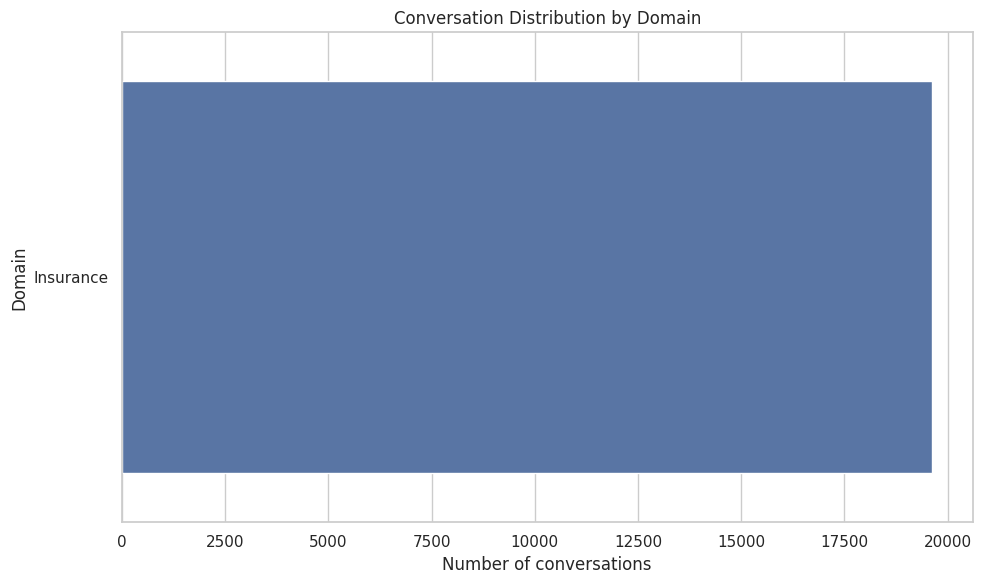

In [9]:
domain_counts = (
    df["domain"]
    .value_counts(dropna=False)
    .rename_axis("domain")
    .reset_index(name="conversation_count")
)

domain_counts["percentage"] = (
    100 * domain_counts["conversation_count"] / len(df)
)

display(domain_counts)

domain_counts.to_csv(
    OUTPUT_DIR / "domain_distribution.csv", index=False
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=domain_counts,
    y="domain",
    x="conversation_count"
)
plt.title("Conversation Distribution by Domain")
plt.xlabel("Number of conversations")
plt.ylabel("Domain")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "domain_distribution.png", dpi=200, bbox_inches="tight")
plt.show()


## 8. Intent distribution

,intent,conversation_count,percentage
0,Loyalty Program,1161,5.917130
1,Delay Management,722,3.679731
2,Replacement vs Refund,626,3.190459
3,Product Feedback,624,3.180266
4,Product Returns,622,3.170073
5,Delivery Delays,622,3.170073
6,Cancellation Policies,561,2.859181
7,Upgrade Requests,559,2.848988
8,Technical Support,558,2.843892
9,Service Complaints,557,2.838795


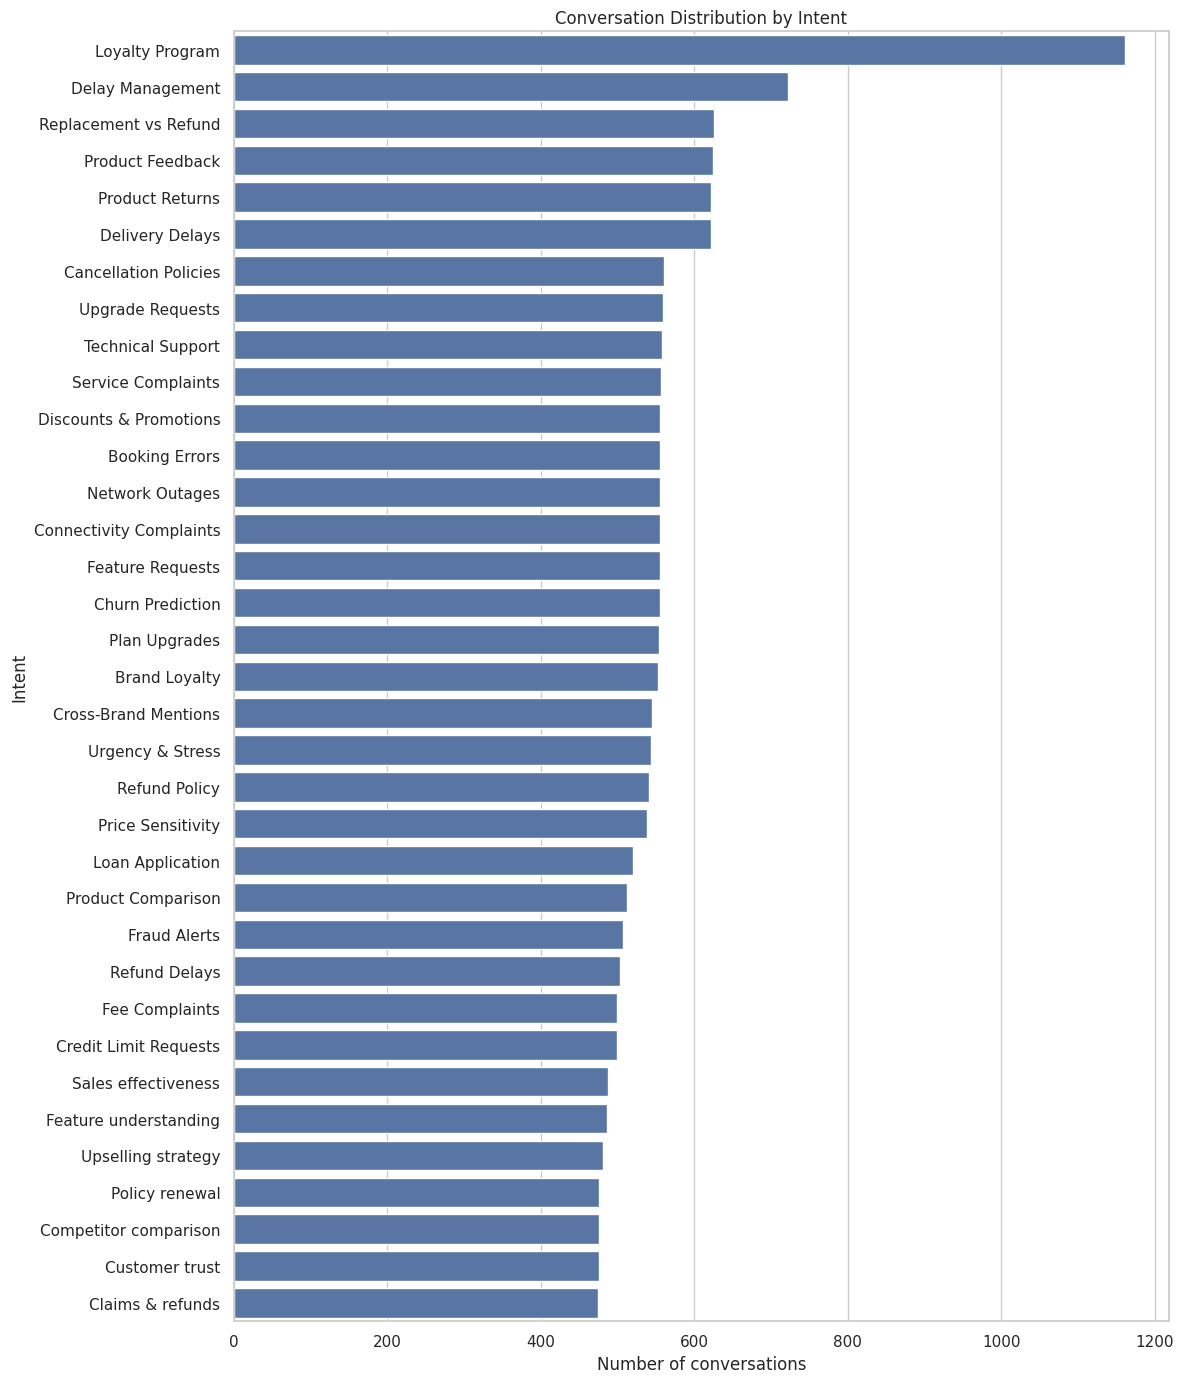

In [10]:
intent_counts = (
    df["intent"]
    .value_counts(dropna=False)
    .rename_axis("intent")
    .reset_index(name="conversation_count")
)

intent_counts["percentage"] = (
    100 * intent_counts["conversation_count"] / len(df)
)

display(intent_counts)

intent_counts.to_csv(
    OUTPUT_DIR / "intent_distribution.csv", index=False
)

plt.figure(figsize=(12, 14))
sns.barplot(
    data=intent_counts,
    y="intent",
    x="conversation_count"
)
plt.title("Conversation Distribution by Intent")
plt.xlabel("Number of conversations")
plt.ylabel("Intent")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "intent_distribution.png", dpi=200, bbox_inches="tight")
plt.show()


## 9. Domain × Intent structure

This is useful for checking whether particular intents are concentrated inside particular domains.


intent,Booking Errors,Brand Loyalty,Cancellation Policies,Churn Prediction,Claims & refunds,Competitor comparison,Connectivity Complaints,Credit Limit Requests,Cross-Brand Mentions,Customer trust,Delay Management,Delivery Delays,Discounts & Promotions,Feature Requests,Feature understanding,Fee Complaints,Fraud Alerts,Loan Application,Loyalty Program,Network Outages,Plan Upgrades,Policy renewal,Price Sensitivity,Product Comparison,Product Feedback,Product Returns,Refund Delays,Refund Policy,Replacement vs Refund,Sales effectiveness,Service Complaints,Technical Support,Upgrade Requests,Upselling strategy,Urgency & Stress
domain,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Insurance,555,553,561,555,475,476,555,499,545,476,722,622,556,555,486,500,507,521,1161,555,554,476,539,512,624,622,504,541,626,488,557,558,559,482,544


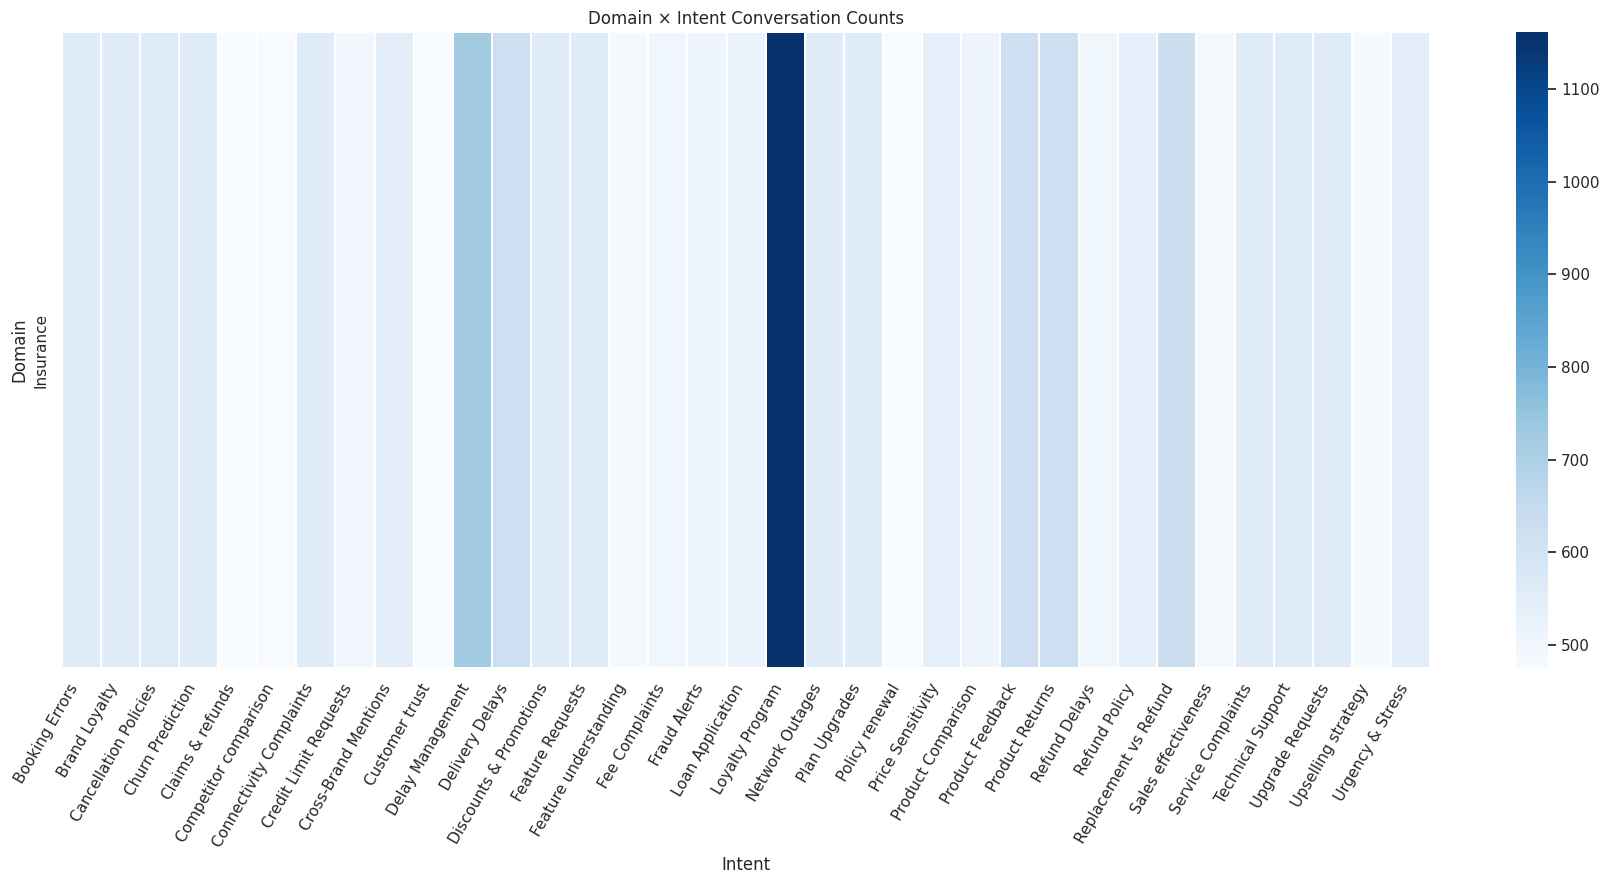

In [11]:
domain_intent = pd.crosstab(
    df["domain"],
    df["intent"]
)

display(domain_intent)

domain_intent.to_csv(
    OUTPUT_DIR / "domain_intent_crosstab.csv"
)

plt.figure(figsize=(18, 9))
sns.heatmap(
    domain_intent,
    annot=False,
    cmap="Blues",
    linewidths=0.2
)
plt.title("Domain × Intent Conversation Counts")
plt.xlabel("Intent")
plt.ylabel("Domain")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "domain_intent_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()


## 10. Reason-for-call analysis

`reason_for_call` is free text rather than a categorical label. We inspect:

- Missingness
- Number of unique reasons
- Most frequent exact reasons
- Reason length


Unique reasons: 19590
Missing reasons: 0

Most common exact reasons:


,count
reason_for_call,
Customer called to address a flight delay and explore rebooking options.,8
Inquiry about loyalty program benefits and flexibility for frequent flyers.,3
Customer called to report a defective item and inquire about resolution options.,2
Customer reported receiving a damaged product and sought resolution.,2
Dispute over an overdraft fee charged due to insufficient funds or pending transaction holds.,2
Customer wanted to explore options for upgrading their current plan.,2
Customer called to resolve a flight delay and explore rebooking options.,2
Inquiry about loyalty program benefits for frequent flyers.,2
Inquiry about loyalty program benefits and treatment of frequent flyers.,2


,count,mean,std,min,25%,50%,75%,max
reason_words,19621.0,15.75939,3.511965,5.0,13.0,16.0,18.0,37.0
reason_chars,19621.0,107.94195,23.035204,31.0,92.0,107.0,122.0,220.0


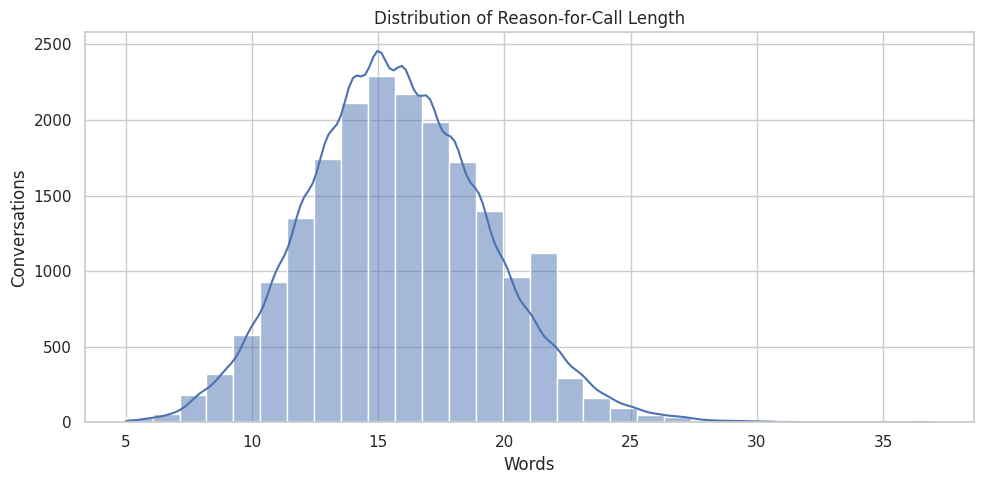

In [12]:
df["reason_words"] = df["reason_for_call"].fillna("").str.split().str.len()
df["reason_chars"] = df["reason_for_call"].fillna("").str.len()

print("Unique reasons:", df["reason_for_call"].nunique())
print("Missing reasons:", df["reason_for_call"].isna().sum())

print("\nMost common exact reasons:")
display(df["reason_for_call"].value_counts().head(20).to_frame("count"))

reason_stats = df[["reason_words", "reason_chars"]].describe().T
display(reason_stats)

plt.figure(figsize=(10, 5))
sns.histplot(df["reason_words"], bins=30, kde=True)
plt.title("Distribution of Reason-for-Call Length")
plt.xlabel("Words")
plt.ylabel("Conversations")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "reason_length_distribution.png", dpi=200, bbox_inches="tight")
plt.show()


## 11. Flatten conversations to turn level

In [13]:
turn_rows = []

for r in data:
    for turn_id, turn in enumerate(r.get("conversation", []), start=1):
        turn_rows.append({
            "transcript_id": r.get("transcript_id"),
            "turn_id": turn_id,
            "speaker": turn.get("speaker"),
            "text": str(turn.get("text", "")).strip(),
            "time_of_interaction": r.get("time_of_interaction"),
            "domain": r.get("domain"),
            "intent": r.get("intent"),
            "reason_for_call": r.get("reason_for_call"),
        })

turns = pd.DataFrame(turn_rows)

turns["time_of_interaction"] = pd.to_datetime(
    turns["time_of_interaction"], errors="coerce"
)

turns["word_count"] = turns["text"].str.split().str.len()
turns["char_count"] = turns["text"].str.len()

print("Turn-level shape:", turns.shape)
display(turns.head(10))


Turn-level shape: (686764, 10)


,transcript_id,turn_id,speaker,text,time_of_interaction,domain,intent,reason_for_call,word_count,char_count
0,ce44aa4b-13b7-4778-b413-15f37ee15f7a,1,Agent,thank you for calling beachfront suites this is isabella nguyen how can i help you today,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,16,88
1,ce44aa4b-13b7-4778-b413-15f37ee15f7a,2,Customer,hi um this is lily kelly i have a question about like um some promotional codes for my upcoming stay in las vegas,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,23,113
2,ce44aa4b-13b7-4778-b413-15f37ee15f7a,3,Agent,sure lily i’d be happy to assist you with that uh can you tell me the dates you’ll be staying,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,20,93
3,ce44aa4b-13b7-4778-b413-15f37ee15f7a,4,Customer,it’s uh from july tenth to july fifteenth i just wanna see if i can um get any discounts or like special offers,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,23,111
4,ce44aa4b-13b7-4778-b413-15f37ee15f7a,5,Agent,absolutely so we currently have a promo code uh summer20 which gives you a twenty percent discount on your stay,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,20,111
5,ce44aa4b-13b7-4778-b413-15f37ee15f7a,6,Customer,oh great so um does that apply to all room types or can i get any like loyalty benefits too,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,20,91
6,ce44aa4b-13b7-4778-b413-15f37ee15f7a,7,Agent,yes um it applies to most room types and since you’re a silver member you’re also eligible for a free upgrade to a d...,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,25,126
7,ce44aa4b-13b7-4778-b413-15f37ee15f7a,8,Customer,really uh that sounds good but i um did see that hilton had some other offers for my stay like in miami,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,22,103
8,ce44aa4b-13b7-4778-b413-15f37ee15f7a,9,Agent,i understand lily it can be tough choosing the best offer can you tell me what specific offers you saw,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,20,102
9,ce44aa4b-13b7-4778-b413-15f37ee15f7a,10,Customer,um i think they had uh a fifty percent off promo for like new users or something like that,2025-11-10 16:23:00,Insurance,Discounts & Promotions,Inquiry about promotional codes and potential loyalty benefits for booking at Beachfront Suites in Las Vegas.,19,90


## 12. Speaker analysis

The speaker field is not limited to exactly `Agent` and `Customer`. The dataset contains named speakers and role-like labels.

We therefore report:
1. Raw speaker distribution.
2. A conservative normalized category:
   - `Agent`
   - `Customer`
   - `Other / Named Speaker`

This avoids pretending that every named speaker can be reliably mapped to a role.


,speaker,turn_count
0,Agent,330420
1,Customer,316449
2,James O'Connor,2098
3,Mia,1482
4,Ethan,1173
5,Chloe,1080
6,Mia Hernandez,984
7,Olivia,958
8,Supervisor,946
9,Chloe Adams,873


,speaker_group,turn_count,percentage
0,Agent,330420,48.112598
1,Customer,316449,46.078274
2,Other / Named Speaker,39895,5.809128


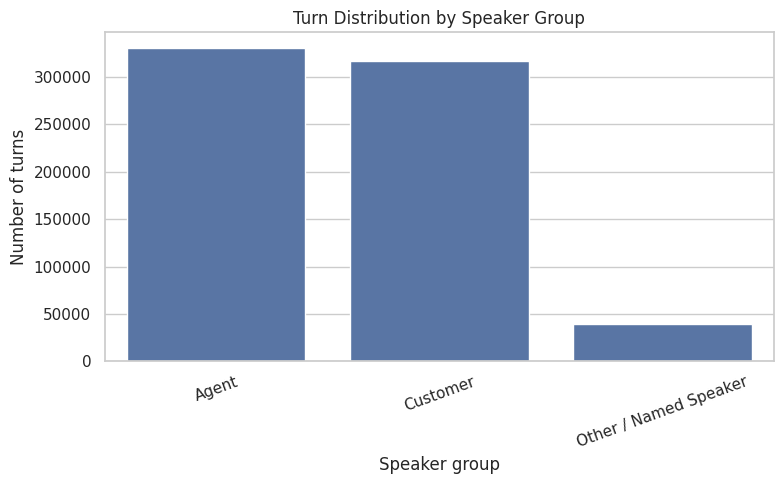

In [14]:
speaker_counts = (
    turns["speaker"]
    .value_counts()
    .rename_axis("speaker")
    .reset_index(name="turn_count")
)

display(speaker_counts.head(30))

def normalize_speaker(s):
    s = str(s).strip().lower()

    if s == "agent":
        return "Agent"
    if s == "customer":
        return "Customer"
    return "Other / Named Speaker"

turns["speaker_group"] = turns["speaker"].map(normalize_speaker)

speaker_group_counts = (
    turns["speaker_group"]
    .value_counts()
    .rename_axis("speaker_group")
    .reset_index(name="turn_count")
)

speaker_group_counts["percentage"] = (
    100 * speaker_group_counts["turn_count"] / len(turns)
)

display(speaker_group_counts)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=speaker_group_counts,
    x="speaker_group",
    y="turn_count"
)
plt.title("Turn Distribution by Speaker Group")
plt.xlabel("Speaker group")
plt.ylabel("Number of turns")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "speaker_group_distribution.png", dpi=200, bbox_inches="tight")
plt.show()


## 13. Conversation length analysis

,turns_per_conversation
count,19621.000000
mean,35.001478
std,6.061825
min,1.000000
25%,30.000000
50%,35.000000
75%,40.000000
max,79.000000


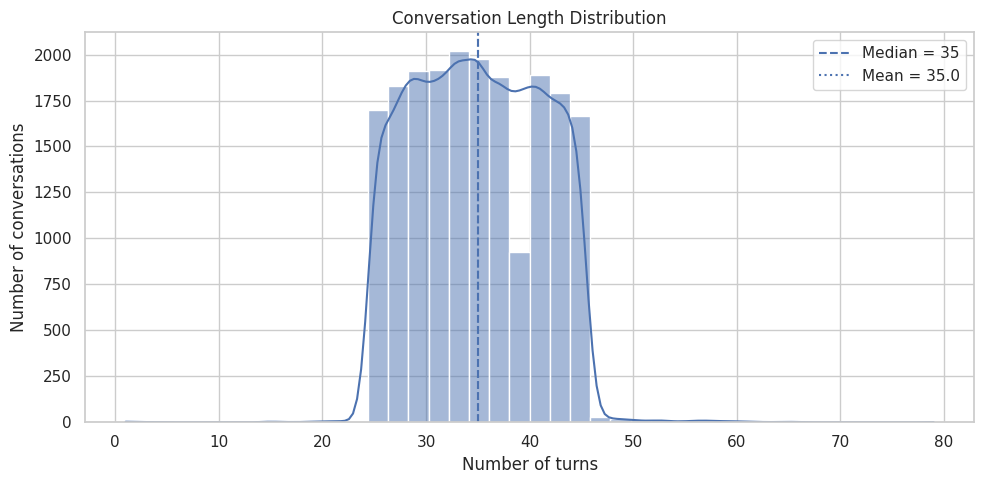

Longest conversations:


,transcript_id,domain,intent,n_turns,conversation_words
13785,dcfb2aee-fc00-4c2b-aa37-14c8882e4011,Insurance,Feature Requests,79,772
16709,e54dc633-b279-4345-a585-61bf9bdcacae,Insurance,Claims & refunds,66,802
11184,f2280f9b-f075-4a2c-8c02-38962fee1747,Insurance,Refund Delays,65,556
5965,2ed83b15-d821-4b2c-a5aa-600233f3b72c,Insurance,Price Sensitivity,64,712
1661,9ee91547-2bb3-4c83-a4e2-4daf62732bea,Insurance,Cancellation Policies,62,508
843,15eb1b36-16c3-4fe4-8693-133c33670c67,Insurance,Service Complaints,61,557
13326,0ab1415d-e03e-403c-8413-198b2d5239d1,Insurance,Feature Requests,61,733
14192,708de90d-22e6-412d-9a57-5c3581e2e897,Insurance,Churn Prediction,60,625
16693,14c2f326-4ad9-4907-b973-9205dff86f23,Insurance,Customer trust,60,441
5480,3babe5f6-859f-4560-b8a1-22f7b87c5ec8,Insurance,Delay Management,59,706


In [15]:
length_stats = df["n_turns"].describe()
display(length_stats.to_frame("turns_per_conversation"))

plt.figure(figsize=(10, 5))
sns.histplot(df["n_turns"], bins=40, kde=True)
plt.axvline(df["n_turns"].median(), linestyle="--", label=f"Median = {df['n_turns'].median():.0f}")
plt.axvline(df["n_turns"].mean(), linestyle=":", label=f"Mean = {df['n_turns'].mean():.1f}")
plt.title("Conversation Length Distribution")
plt.xlabel("Number of turns")
plt.ylabel("Number of conversations")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "conversation_length_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

print("Longest conversations:")
display(
    df.nlargest(10, "n_turns")[
        ["transcript_id", "domain", "intent", "n_turns", "conversation_words"]
    ]
)


## 14. Conversation length by intent

This helps identify intents that systematically generate shorter or longer conversations.


,conversations,mean_turns,median_turns,mean_words
intent,,,,
Technical Support,558,35.878136,36.0,506.722222
Churn Prediction,555,35.538739,36.0,560.169369
Fraud Alerts,507,35.453649,36.0,524.366864
Feature understanding,486,35.358025,35.0,613.300412
Discounts & Promotions,556,35.197842,35.0,565.832734
Claims & refunds,475,35.193684,35.0,541.858947
Cancellation Policies,561,35.188948,35.0,564.333333
Plan Upgrades,554,35.182310,35.0,525.476534
Urgency & Stress,544,35.176471,35.0,529.966912


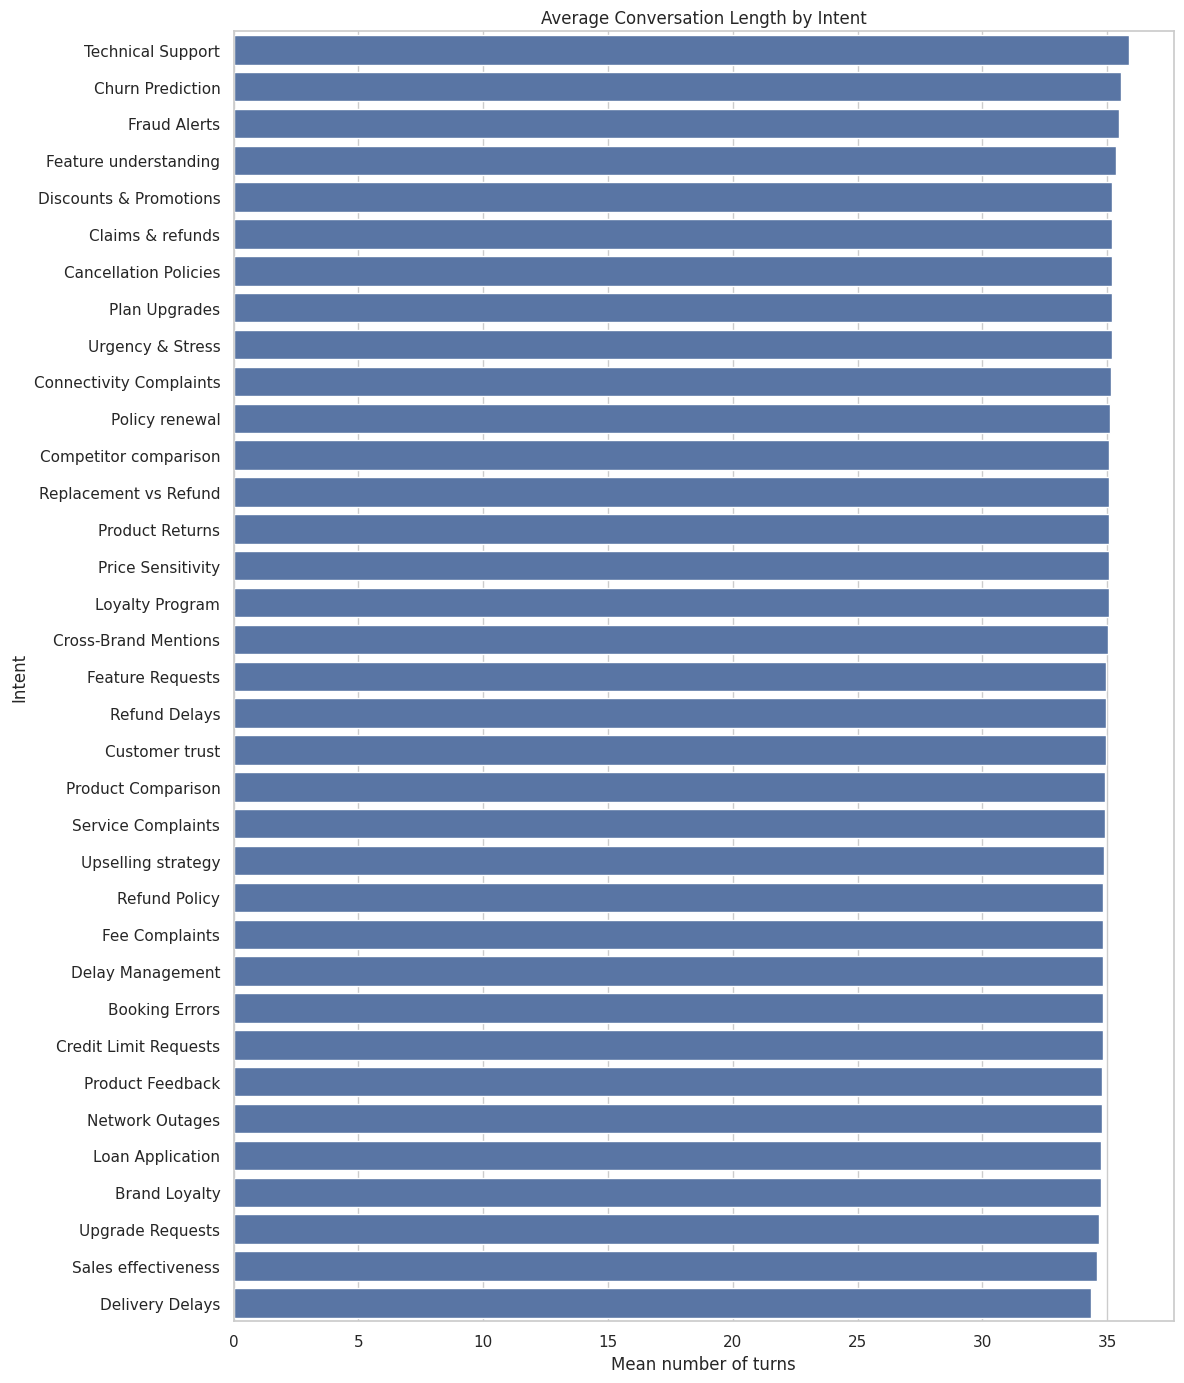

In [16]:
intent_length = (
    df.groupby("intent")
      .agg(
          conversations=("transcript_id", "count"),
          mean_turns=("n_turns", "mean"),
          median_turns=("n_turns", "median"),
          mean_words=("conversation_words", "mean"),
      )
      .sort_values("mean_turns", ascending=False)
)

display(intent_length)

plt.figure(figsize=(12, 14))
sns.barplot(
    data=intent_length.reset_index(),
    y="intent",
    x="mean_turns"
)
plt.title("Average Conversation Length by Intent")
plt.xlabel("Mean number of turns")
plt.ylabel("Intent")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mean_turns_by_intent.png", dpi=200, bbox_inches="tight")
plt.show()


## 15. Turn-level text length

,count,mean,std,min,25%,50%,75%,max
word_count,686764.0,15.727167,6.337435,0.0,12.0,16.0,20.0,603.0
char_count,686764.0,83.945186,35.939159,0.0,60.0,83.0,107.0,3181.0


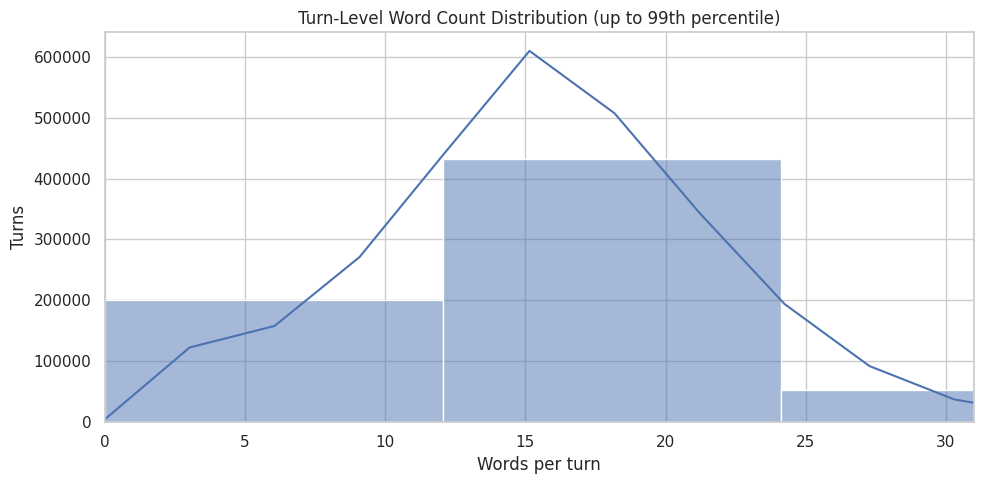

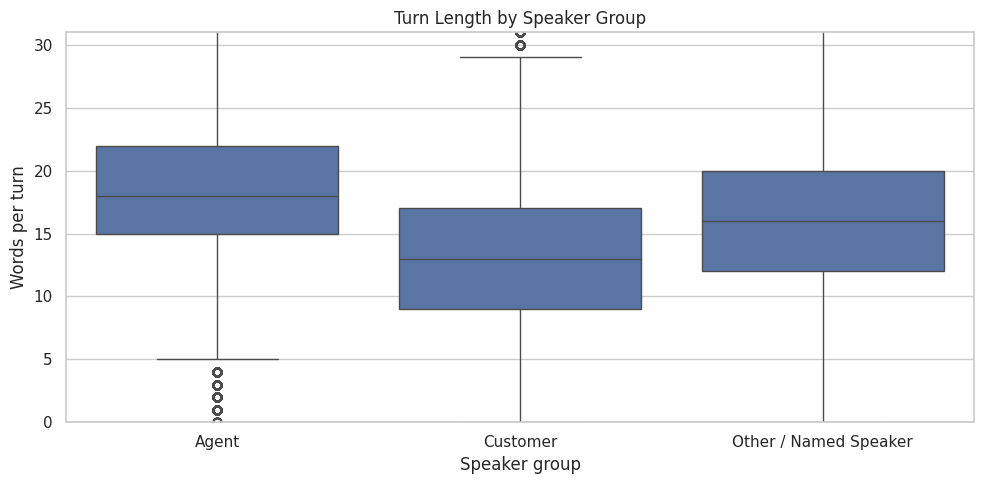

In [17]:
turn_text_stats = turns[["word_count", "char_count"]].describe().T
display(turn_text_stats)

plt.figure(figsize=(10, 5))
sns.histplot(turns["word_count"], bins=50, kde=True)
plt.xlim(0, turns["word_count"].quantile(0.99))
plt.title("Turn-Level Word Count Distribution (up to 99th percentile)")
plt.xlabel("Words per turn")
plt.ylabel("Turns")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "turn_word_count_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=turns,
    x="speaker_group",
    y="word_count"
)
plt.ylim(0, turns["word_count"].quantile(0.99))
plt.title("Turn Length by Speaker Group")
plt.xlabel("Speaker group")
plt.ylabel("Words per turn")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "turn_length_by_speaker.png", dpi=200, bbox_inches="tight")
plt.show()


## 16. Temporal analysis

The timestamp is a conversation-level field. We inspect:

- Conversations by date
- Conversations by hour
- Conversations by day of week
- Intent distribution over time

These are descriptive patterns only; they do not establish causality.


,date,conversation_count
0,2025-11-04,243
1,2025-11-05,891
2,2025-11-06,2802
3,2025-11-07,2949
4,2025-11-08,2744


,hour,conversation_count
0,9,2506
1,10,2482
2,11,2429
3,12,2514
4,13,2439
5,14,2459
6,15,2441
7,16,2351


,day_of_week,conversation_count
0,Monday,2784
1,Tuesday,2828
2,Wednesday,2719
3,Thursday,2802
4,Friday,2949
5,Saturday,2744
6,Sunday,2795


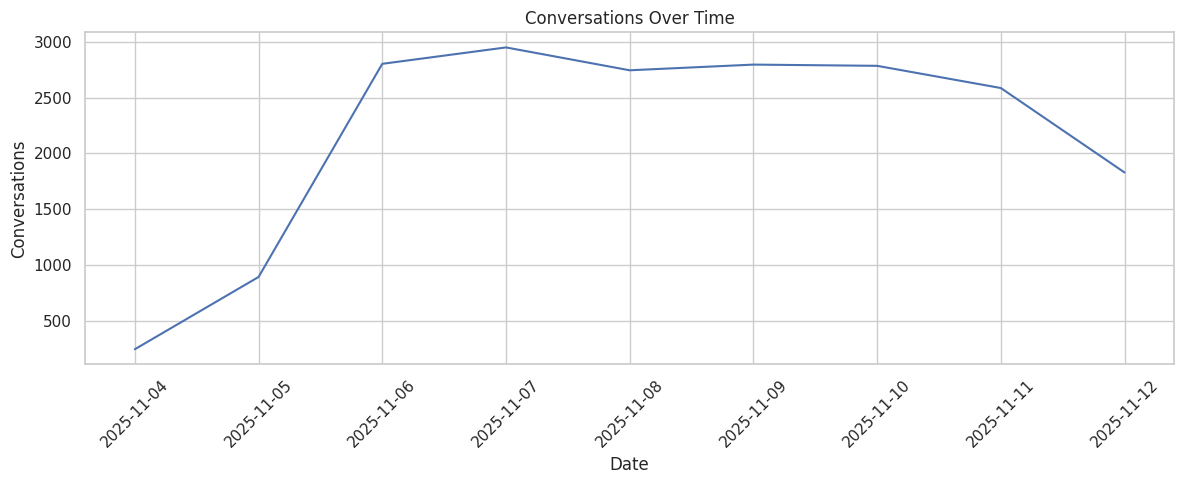

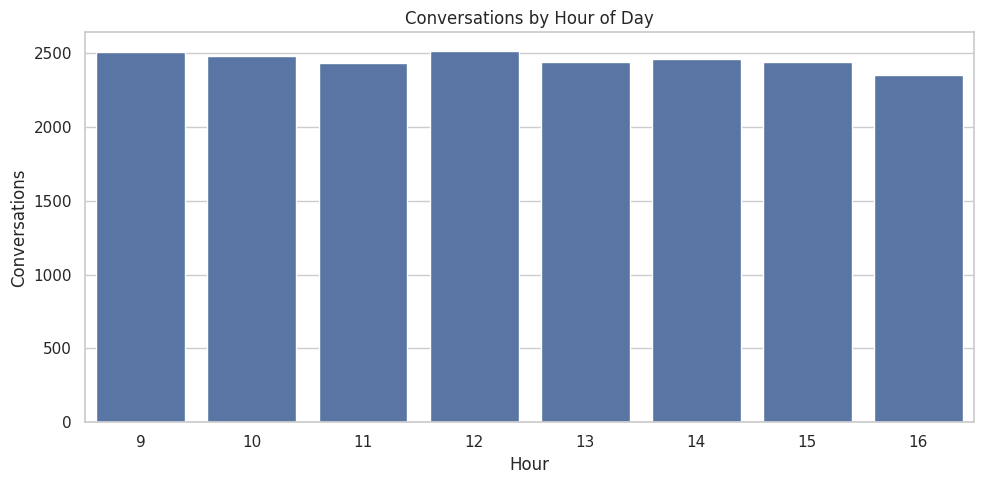

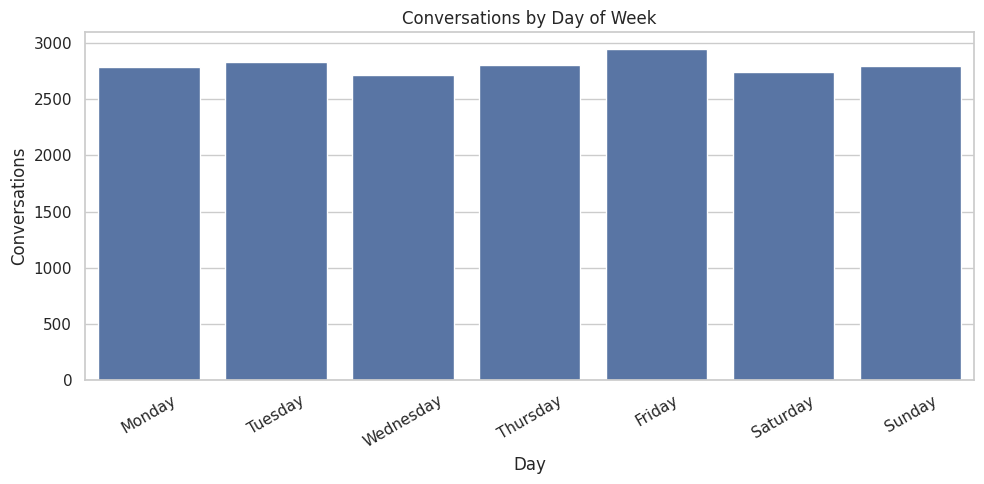

In [18]:
daily_counts = (
    df.groupby("date")
      .size()
      .rename("conversation_count")
      .reset_index()
)

hour_counts = (
    df["hour"]
    .value_counts()
    .sort_index()
    .rename_axis("hour")
    .reset_index(name="conversation_count")
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_counts = (
    df["day_of_week"]
    .value_counts()
    .reindex(weekday_order)
    .fillna(0)
    .rename_axis("day_of_week")
    .reset_index(name="conversation_count")
)

display(daily_counts.head())
display(hour_counts)
display(weekday_counts)

fig = plt.figure(figsize=(12, 5))
sns.lineplot(data=daily_counts, x="date", y="conversation_count")
plt.title("Conversations Over Time")
plt.xlabel("Date")
plt.ylabel("Conversations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "conversations_over_time.png", dpi=200, bbox_inches="tight")
plt.show()

fig = plt.figure(figsize=(10, 5))
sns.barplot(data=hour_counts, x="hour", y="conversation_count")
plt.title("Conversations by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Conversations")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "conversations_by_hour.png", dpi=200, bbox_inches="tight")
plt.show()

fig = plt.figure(figsize=(10, 5))
sns.barplot(data=weekday_counts, x="day_of_week", y="conversation_count")
plt.title("Conversations by Day of Week")
plt.xlabel("Day")
plt.ylabel("Conversations")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "conversations_by_weekday.png", dpi=200, bbox_inches="tight")
plt.show()


## 17. Filler-word analysis

,filler,count,per_1000_words
1,um,346946,32.122096
0,uh,207502,19.211633
8,just,107216,9.926624
2,like,106171,9.829873
7,really,59632,5.521046
5,okay,46999,4.351416
3,you know,37942,3.512871
4,yeah,31658,2.931065
6,actually,11890,1.100839


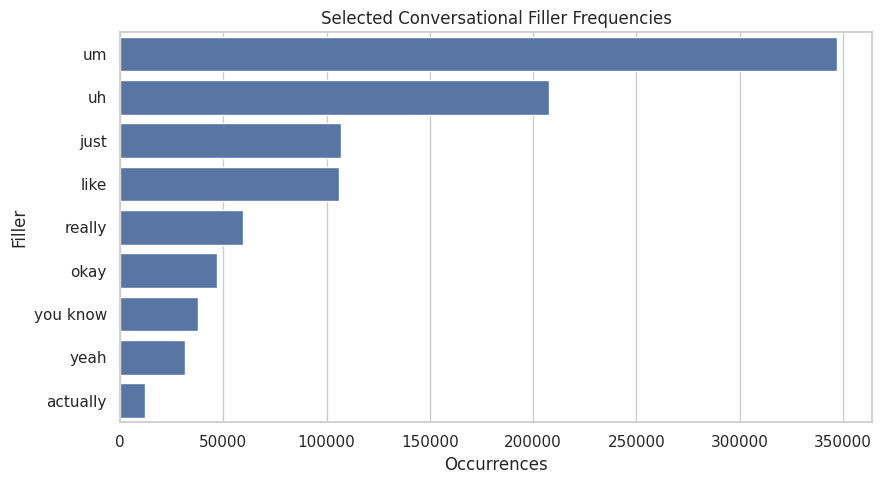

In [19]:
# Common conversational fillers visible in the transcripts.
# This is descriptive text analysis, not sentiment detection.

FILLERS = [
    "uh", "um", "like", "you know", "yeah",
    "okay", "actually", "really", "just"
]

all_text = " ".join(turns["text"].fillna("").str.lower())

filler_rows = []

for filler in FILLERS:
    pattern = r"\b" + re.escape(filler) + r"\b"
    count = len(re.findall(pattern, all_text))
    filler_rows.append({
        "filler": filler,
        "count": count,
        "per_1000_words": 1000 * count / max(len(all_text.split()), 1)
    })

filler_df = pd.DataFrame(filler_rows).sort_values("count", ascending=False)
display(filler_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=filler_df, x="count", y="filler")
plt.title("Selected Conversational Filler Frequencies")
plt.xlabel("Occurrences")
plt.ylabel("Filler")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "filler_frequency.png", dpi=200, bbox_inches="tight")
plt.show()


## 18. Basic vocabulary statistics

We calculate:

- Total word tokens
- Unique words
- Type-token ratio
- Most frequent words after removing a small set of conversational stopwords

This is intended for dataset characterization rather than NLP modeling.


,value
Total word tokens,1.111548e+07
Unique word types,1.594200e+04
Type-token ratio,1.434216e-03
Filtered tokens,7.103890e+06
Filtered unique types,1.591000e+04


,word,count
0,your,164817
1,can,149047
2,s,128693
3,if,72138
4,what,67902
5,right,66695
6,have,64092
7,about,63869
8,really,59632
9,me,58693


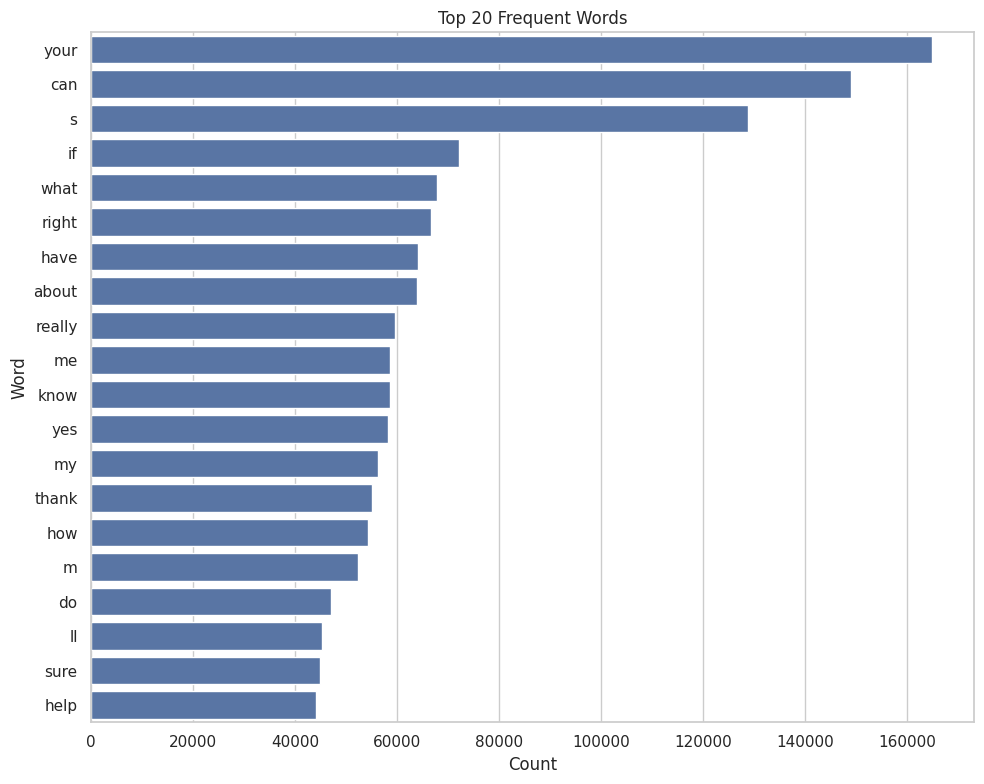

In [20]:
STOPWORDS = {
    "the", "a", "an", "and", "or", "but", "to", "of", "in", "on",
    "for", "with", "is", "are", "was", "were", "be", "been", "i",
    "you", "we", "they", "it", "this", "that", "so", "um", "uh",
    "like", "just", "okay", "yeah"
}

tokens = re.findall(r"[a-zA-Z']+", all_text)
filtered_tokens = [t for t in tokens if t not in STOPWORDS]

token_count = len(tokens)
unique_token_count = len(set(tokens))
filtered_unique = len(set(filtered_tokens))

vocab_stats = pd.Series({
    "Total word tokens": token_count,
    "Unique word types": unique_token_count,
    "Type-token ratio": unique_token_count / max(token_count, 1),
    "Filtered tokens": len(filtered_tokens),
    "Filtered unique types": filtered_unique,
})

display(vocab_stats.to_frame("value"))

word_counts = Counter(filtered_tokens)

top_words = pd.DataFrame(
    word_counts.most_common(30),
    columns=["word", "count"]
)

display(top_words)

top_words.to_csv(
    OUTPUT_DIR / "top_words.csv", index=False
)

plt.figure(figsize=(10, 8))
sns.barplot(data=top_words.head(20), y="word", x="count")
plt.title("Top 20 Frequent Words")
plt.xlabel("Count")
plt.ylabel("Word")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_words.png", dpi=200, bbox_inches="tight")
plt.show()


## 19. Dialogue structure: alternating speakers

A useful conversational feature is whether turns alternate between speaker groups.

We calculate, per conversation:

- Number of speaker-group changes
- Fraction of adjacent turns with a speaker change
- Number of consecutive same-speaker turns


,transcript_id,n_turns,speaker_changes,speaker_change_rate,same_speaker_adjacent_pairs
0,ce44aa4b-13b7-4778-b413-15f37ee15f7a,27,26.0,1.0,0.0
1,6447a610-7803-4e29-918f-7255ece57195,29,28.0,1.0,0.0
2,1e47a0f1-6334-45b3-8d04-84f8795d8d60,29,28.0,1.0,0.0
3,1fdc6e49-fdb1-4b0e-9ede-f207389e236e,41,40.0,1.0,0.0
4,d0bb846f-8d9d-4223-9d10-2657c29c4244,41,40.0,1.0,0.0


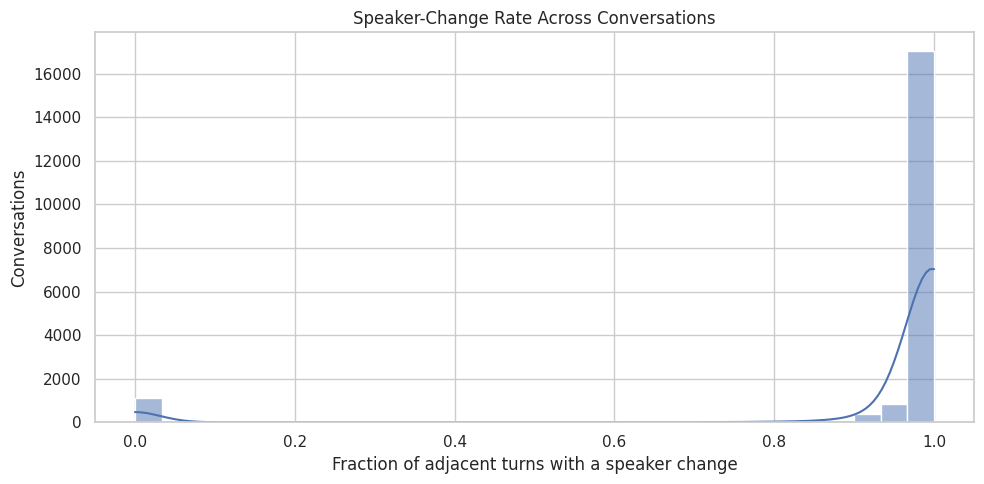

In [21]:
def dialogue_structure(group):
    speakers = group["speaker_group"].tolist()

    if len(speakers) <= 1:
        return pd.Series({
            "speaker_changes": 0,
            "speaker_change_rate": 0.0,
            "same_speaker_adjacent_pairs": 0
        })

    changes = sum(
        speakers[i] != speakers[i - 1]
        for i in range(1, len(speakers))
    )

    same_pairs = (len(speakers) - 1) - changes

    return pd.Series({
        "speaker_changes": changes,
        "speaker_change_rate": changes / (len(speakers) - 1),
        "same_speaker_adjacent_pairs": same_pairs
    })

structure = (
    turns.groupby("transcript_id", sort=False)
         .apply(dialogue_structure)
         .reset_index()
)

df = df.merge(structure, on="transcript_id", how="left")

display(
    df[
        ["transcript_id", "n_turns",
         "speaker_changes", "speaker_change_rate",
         "same_speaker_adjacent_pairs"]
    ].head()
)

plt.figure(figsize=(10, 5))
sns.histplot(df["speaker_change_rate"], bins=30, kde=True)
plt.title("Speaker-Change Rate Across Conversations")
plt.xlabel("Fraction of adjacent turns with a speaker change")
plt.ylabel("Conversations")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "speaker_change_rate.png", dpi=200, bbox_inches="tight")
plt.show()


## 20. Potential data-quality checks

The checks below flag records that deserve inspection before retrieval/modeling:

- Missing text
- Empty conversations
- Duplicate transcript IDs
- Duplicate full conversations
- Extremely short/long conversations
- Unusual speaker counts
- Missing timestamps/categories


In [22]:
quality_report = {
    "empty_conversations": int((df["n_turns"] == 0).sum()),
    "missing_transcript_id": int(df["transcript_id"].isna().sum()),
    "missing_timestamp": int(df["time_of_interaction"].isna().sum()),
    "missing_domain": int(df["domain"].isna().sum()),
    "missing_intent": int(df["intent"].isna().sum()),
    "missing_reason": int(df["reason_for_call"].isna().sum()),
    "duplicate_transcript_ids": int(df["transcript_id"].duplicated().sum()),
    "duplicate_full_conversations": int(df["conversation_text"].duplicated().sum()),
    "one_turn_conversations": int((df["n_turns"] == 1).sum()),
    "very_long_conversations_60_plus": int((df["n_turns"] >= 60).sum()),
}

display(pd.Series(quality_report, name="count").to_frame())


,count
empty_conversations,0
missing_transcript_id,0
missing_timestamp,0
missing_domain,0
missing_intent,0
missing_reason,0
duplicate_transcript_ids,0
duplicate_full_conversations,0
one_turn_conversations,3
very_long_conversations_60_plus,9


In [23]:
# Inspect suspicious records
suspicious = df[
    (df["n_turns"] <= 1) |
    (df["n_turns"] >= 60) |
    (df["n_speakers"] >= 8)
].copy()

print("Suspicious-record count:", len(suspicious))

display(
    suspicious[
        ["transcript_id", "domain", "intent",
         "n_turns", "n_speakers", "reason_for_call"]
    ].head(50)
)


Suspicious-record count: 13


,transcript_id,domain,intent,n_turns,n_speakers,reason_for_call
843,15eb1b36-16c3-4fe4-8693-133c33670c67,Insurance,Service Complaints,61,2,Customer called to report a cleanliness issue with his room at Beachfront Suites in New York City.
1661,9ee91547-2bb3-4c83-a4e2-4daf62732bea,Insurance,Cancellation Policies,62,2,Inquiry about strict cancellation fees and seeking a waiver.
3608,4e9f931b-c7f0-4798-bfc5-2554d248ab4a,Insurance,Price Sensitivity,1,1,Customer Carter Watson called to address a fare change complaint and understand AeroLink's pricing policy in relatio...
3788,f9e9ffa9-023d-4b59-8fbc-18de66aba567,Insurance,Delay Management,1,1,Customer called to resolve a flight delay and discuss rebooking options.
4931,696baee4-78c5-487c-997d-499e0354a3d8,Insurance,Cross-Brand Mentions,32,8,Customer contacted to compare SkyBridge Airlines' pricing and policies against a competing airline (Delta).
5965,2ed83b15-d821-4b2c-a5aa-600233f3b72c,Insurance,Price Sensitivity,64,2,Customer called to discuss ticket pricing concerns and complaints about Economy fare class service.
11184,f2280f9b-f075-4a2c-8c02-38962fee1747,Insurance,Refund Delays,65,2,Luke called to check on the status of a delayed refund he was expecting from NorthPeak Financial.
11472,09186fc2-131f-467a-ab4f-9745769d7c1b,Insurance,Loan Application,1,1,"The customer, Lily Watson, called to understand the differences between fixed and variable interest rates for a pers..."
13326,0ab1415d-e03e-403c-8413-198b2d5239d1,Insurance,Feature Requests,61,2,Customer Dylan Brooks called to inquire about new service features and evaluate the suitability of the Unlimited Dat...
13785,dcfb2aee-fc00-4c2b-aa37-14c8882e4011,Insurance,Feature Requests,79,2,Customer inquired about adding a new coverage feature to his insurance policy and its impact on long-term premiums.


## 21. Intent/domain balance statistics

For retrieval experiments, it is useful to quantify how balanced the dataset is across categories.

We report:

- Largest category
- Smallest category
- Max/min ratio
- Shannon entropy


In [24]:
def distribution_stats(series):
    counts = series.value_counts()
    p = counts / counts.sum()

    entropy = -(p * np.log2(p)).sum()

    return pd.Series({
        "categories": len(counts),
        "largest_category_count": counts.max(),
        "smallest_category_count": counts.min(),
        "max_min_ratio": counts.max() / max(counts.min(), 1),
        "shannon_entropy_bits": entropy
    })

balance_report = pd.DataFrame({
    "domain": distribution_stats(df["domain"]),
    "intent": distribution_stats(df["intent"])
})

display(balance_report)


,domain,intent
categories,1.0,35.000000
largest_category_count,19621.0,1161.000000
smallest_category_count,19621.0,475.000000
max_min_ratio,1.0,2.444211
shannon_entropy_bits,-0.0,5.104256


## 22. Intent × conversation-length relationship

Rather than only looking at counts, compare the distribution of conversation lengths across intents.

The boxplot is capped at the 95th percentile for readability.


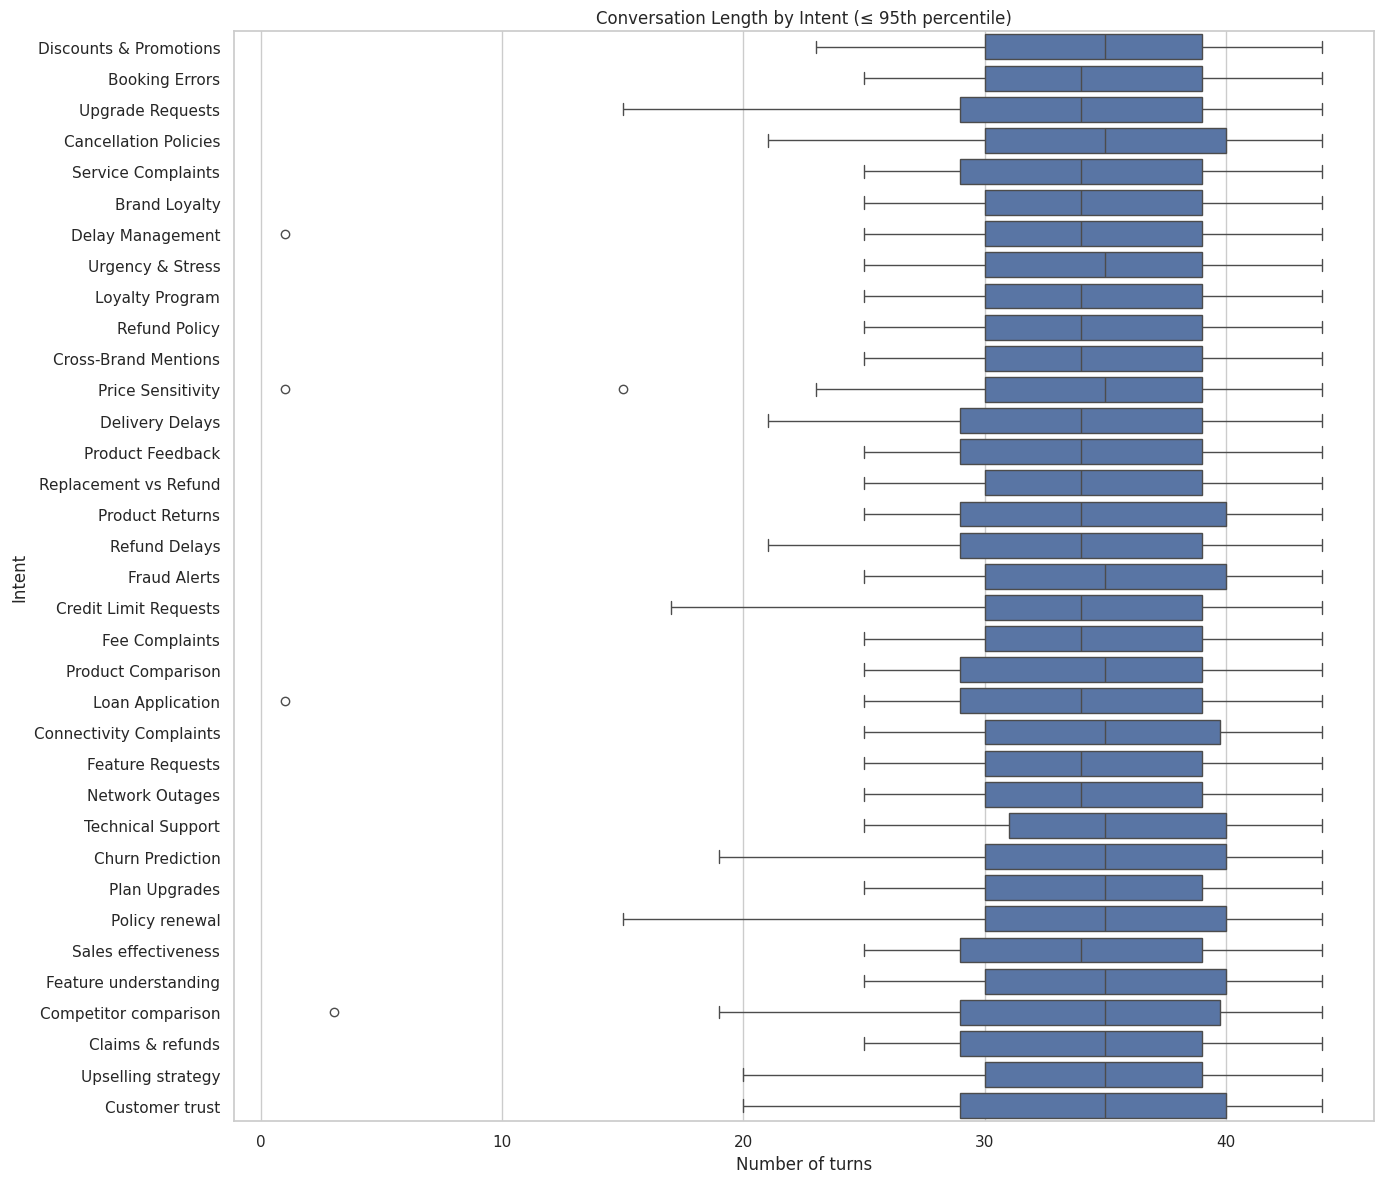

In [25]:
p95 = df["n_turns"].quantile(0.95)

plot_df = df[df["n_turns"] <= p95].copy()

plt.figure(figsize=(14, 12))
sns.boxplot(
    data=plot_df,
    y="intent",
    x="n_turns"
)
plt.title("Conversation Length by Intent (≤ 95th percentile)")
plt.xlabel("Number of turns")
plt.ylabel("Intent")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "conversation_length_by_intent_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()


## 23. Correlation between basic conversation features

These features are descriptive:

- turns
- words
- characters
- number of speakers
- speaker-change rate


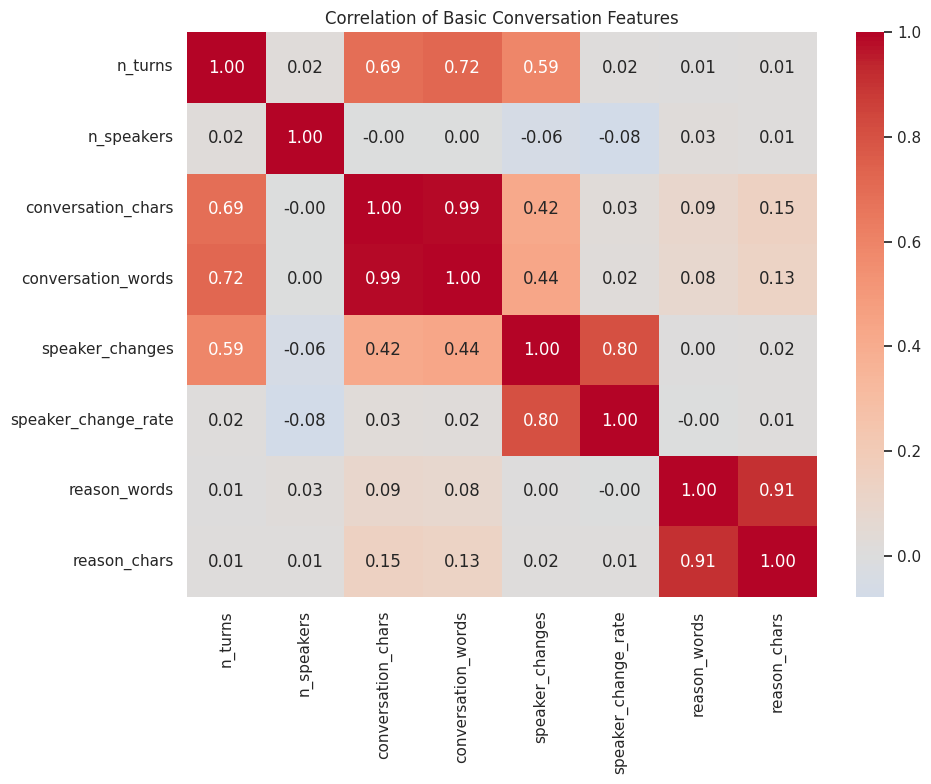

In [26]:
numeric_features = [
    "n_turns",
    "n_speakers",
    "conversation_chars",
    "conversation_words",
    "speaker_changes",
    "speaker_change_rate",
    "reason_words",
    "reason_chars"
]

corr = df[numeric_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation of Basic Conversation Features")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()


## 24. Export EDA tables

Save the cleaned conversation-level and turn-level tables so the next RAG notebook does not need to repeat the flattening step.


In [27]:
# Save useful tables
df.to_parquet(
    OUTPUT_DIR / "conversation_level_eda.parquet",
    index=False
)

turns.to_parquet(
    OUTPUT_DIR / "turn_level_eda.parquet",
    index=False
)

df.to_csv(
    OUTPUT_DIR / "conversation_level_eda.csv",
    index=False
)

turns.to_csv(
    OUTPUT_DIR / "turn_level_eda.csv",
    index=False
)

intent_length.to_csv(
    OUTPUT_DIR / "intent_length_statistics.csv"
)

speaker_counts.to_csv(
    OUTPUT_DIR / "speaker_distribution.csv",
    index=False
)

with open(OUTPUT_DIR / "eda_overview.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            k: (v.item() if isinstance(v, np.generic) else str(v) if isinstance(v, (pd.Timestamp,)) else v)
            for k, v in overview.to_dict().items()
        },
        f,
        indent=2
    )

print("EDA outputs saved to:", OUTPUT_DIR.resolve())


EDA outputs saved to: /kaggle/working/task1_eda_outputs


# 25. EDA conclusions / checklist

Run this final cell after the notebook to print a compact summary for the report.

### What this EDA establishes

- Dataset size and nested conversation structure.
- Distribution of conversations across domains and intents.
- Conversation-length variability.
- Speaker-role variability and named-speaker presence.
- Temporal distribution of interactions.
- Turn-level and conversation-level text statistics.
- Basic dialogue structure and speaker alternation.
- Data-quality issues requiring attention before modeling.

### Important modeling implication

The dataset contains **intent** and **reason-for-call**, but no universal explicit `business_event` or `outcome` field. Therefore, downstream RAG analysis should distinguish:

**retrieved evidence → descriptive interpretation**

from

**explicitly labeled outcome/event → outcome analysis**

If event-level analysis is required later, an explicit labeling/heuristic-validation step should be added rather than silently treating intent as outcome.


In [28]:
print("=" * 70)
print("TASK 1 EDA SUMMARY")
print("=" * 70)

print(f"Conversations        : {len(df):,}")
print(f"Total turns          : {int(df['n_turns'].sum()):,}")
print(f"Unique domains       : {df['domain'].nunique():,}")
print(f"Unique intents       : {df['intent'].nunique():,}")
print(f"Unique raw speakers  : {turns['speaker'].nunique():,}")
print(f"Mean turns/call      : {df['n_turns'].mean():.2f}")
print(f"Median turns/call    : {df['n_turns'].median():.0f}")
print(f"Mean words/call      : {df['conversation_words'].mean():.2f}")

print("\nTop 10 intents:")
display(intent_counts.head(10))

print("\nTop domains:")
display(domain_counts)

print("\nEDA output directory:")
print(OUTPUT_DIR.resolve())


TASK 1 EDA SUMMARY
Conversations        : 19,621
Total turns          : 686,764
Unique domains       : 1
Unique intents       : 35
Unique raw speakers  : 661
Mean turns/call      : 35.00
Median turns/call    : 35
Mean words/call      : 550.47

Top 10 intents:


,intent,conversation_count,percentage
0,Loyalty Program,1161,5.917130
1,Delay Management,722,3.679731
2,Replacement vs Refund,626,3.190459
3,Product Feedback,624,3.180266
4,Product Returns,622,3.170073
5,Delivery Delays,622,3.170073
6,Cancellation Policies,561,2.859181
7,Upgrade Requests,559,2.848988
8,Technical Support,558,2.843892
9,Service Complaints,557,2.838795



Top domains:


,domain,conversation_count,percentage
0,Insurance,19621,100.0



EDA output directory:
/kaggle/working/task1_eda_outputs
